# Stage 1: estimating a shuffled deck from a sample of its cards

A deck of `n` cards is shuffled by random transpositions and we only see `m` cards chosen at random. How well does their mean displacement `AD_hat_m` pin down the equilibrium displacement `AD_inf = (n^2-1)/(3n)`?

This notebook goes through the RSI results in order: unbiasedness, the variance law, the bias of a fixed window, and the conjugate posterior. Everything uses the code in `src/rsi_shuffle`, and every number comes from a seeded run.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from rsi_shuffle import shuffle, estimator, bayes, theory
rng = np.random.default_rng(2026)
n, R = 512, 2000
t_mix = shuffle.mixing_time(n)
print(f"n = {n}, t_mix = {t_mix}, AD_inf = {theory.ad_inf(n):.2f}")

n = 512, t_mix = 1597, AD_inf = 170.67


## 1. Shuffle to the mixing time

`R` independent decks, `t_mix = round(n ln n / 2)` independent-pair swaps each. The mean displacement of the full deck should sit on `AD_inf`.

In [2]:
perm = shuffle.shuffle_decks(n, t_mix, R, rng)
d = shuffle.displacements(perm)
ad = d.mean(axis=1)
print(f"mean AD after t_mix: {ad.mean():.2f} +/- {ad.std(ddof=1)/np.sqrt(R):.2f}   (AD_inf = {theory.ad_inf(n):.2f})")
print(f"sd of AD over decks: {ad.std(ddof=1):.2f}   exact: {theory.var_ad(n)**0.5:.2f}")

mean AD after t_mix: 170.24 +/- 0.11   (AD_inf = 170.67)
sd of AD over decks: 4.93   exact: 4.77


The sd of the full-deck `AD` is small but not zero. Keep it in mind: it is the floor of the extension.

## 2. Partial observation: unbiased, with variance close to `n^2/(18 m)`

In [3]:
ms = [32, 64, 128, 256]
rows = []
for m in ms:
    est = estimator.uniform_sample_estimate(d, m, rng)
    rows.append((m, est.mean(), est.var(ddof=1), n**2/(18*m), theory.estimator_variance(n, m)))
print(f"{'m':>5} {'mean':>8} {'var (sim)':>10} {'n^2/18m':>9} {'exact law':>10}")
for r in rows: print(f"{r[0]:>5} {r[1]:>8.2f} {r[2]:>10.1f} {r[3]:>9.1f} {r[4]:>10.1f}")

    m     mean  var (sim)   n^2/18m  exact law
   32   170.41      434.8     455.1      449.6
   64   170.93      225.3     227.6      222.0
  128   170.02      112.9     113.8      108.2
  256   170.34       51.2      56.9       51.3


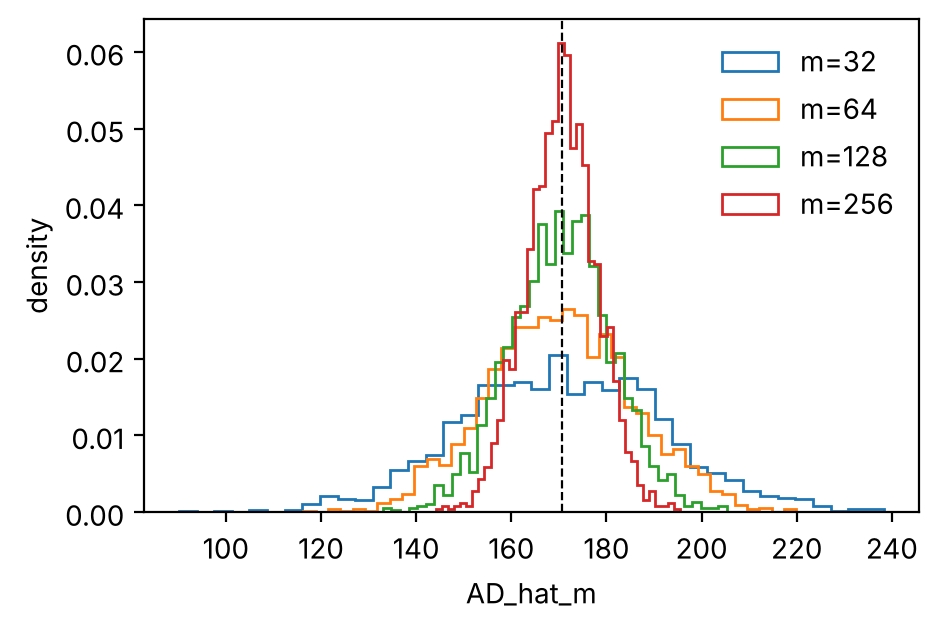

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for m in ms:
    ax.hist(estimator.uniform_sample_estimate(d, m, rng), bins=40, histtype="step", density=True, label=f"m={m}")
ax.axvline(theory.ad_inf(n), color="k", lw=0.8, ls="--")
ax.set_xlabel("AD_hat_m"); ax.set_ylabel("density"); ax.legend(frameon=False); plt.show()

The simulated variance follows the leading-order law `n^2/(18 m)` to within a few percent for small `m` and falls below it as `m/n` grows. The exact law (RSI Eq. E.3) explains that drop through the finite-population factor.

## 3. Why the sample must be random

The first `m` cards sit at the edge of the deck, where `E|pi(i)-i|` is largest.

In [5]:
first = estimator.first_m_window_estimate(d, 32)
unif = estimator.uniform_sample_estimate(d, 32, rng)
print(f"uniform sample, m=32:  mean {unif.mean():.1f}")
print(f"first 32 cards:        mean {first.mean():.1f}   (AD_inf = {theory.ad_inf(n):.1f})")

uniform sample, m=32:  mean 170.1
first 32 cards:        mean 240.7   (AD_inf = 170.7)


## 4. One posterior

Take a single deck, observe `m = 128` cards, and update the Gaussian prior `N(AD_inf, 100^2)`.

In [6]:
y = estimator.uniform_sample_estimate(d[:1], 128, rng)[0]
post = bayes.conjugate_posterior(y, bayes.sampling_sd(n, 128), mu0=theory.ad_inf(n), sigma0=100.0)
lo, hi = post.interval()
print(f"observed AD_hat = {y:.1f};  posterior N({post.mean:.1f}, {post.sd:.2f}^2);  95% interval ({lo:.1f}, {hi:.1f})")
print(f"relative half-width: {(hi-lo)/2/theory.ad_inf(n):.3f}    (1.96 / sqrt(2m) = {1.96/np.sqrt(256):.3f})")

observed AD_hat = 148.7;  posterior N(149.0, 10.61^2);  95% interval (128.2, 169.8)
relative half-width: 0.122    (1.96 / sqrt(2m) = 0.122)


The relative width depends on `m` only, not on `n`, which is the scale-invariance result. The extension asks what happens when `m` is large: the sampling term shrinks, but a term that does not depend on `m` remains. That is `02_the_floor.ipynb`.